# EdTech Learning Analytics: Student Performance, Engagement & Dropout Risk

**Author:** Ronit Kumar  |  **Tools:** SQL (SQLite / MySQL 8), Python (Pandas, NumPy, SciPy, scikit-learn, Matplotlib)

### Business problem
A coaching institute runs JEE, NEET and Foundation batches (online and offline) with weekly Computer-Based Tests (CBTs), daily attendance and weekly homework. Management wants to know:

1. How are students performing overall, and **which topics are weakest**?
2. Do **attendance** and **homework** actually move test scores, and by how much?
3. How do **online vs offline** batches and **teachers** compare?
4. **Who is likely to drop out**, and can we spot them early enough to intervene?

### Data
Synthetic data for 1,500 students over one term (Jul to Dec 2025), generated by `scripts/generate_data.py` with a fixed seed. It's modelled on a real coaching-institute platform: 11 related tables, ~350K rows. All names are fictional.

### Notebook outline
1. Setup & data loading  2. Data quality checks  3. KPI overview  4. Topic analysis  5. Attendance & homework impact  6. Trends over the term  7. Online vs offline & teachers  8. Dropout analysis & early-warning model  9. Recommendations

In [1]:
import sqlite3
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy import stats

ROOT = Path("..")
DB = ROOT / "data" / "edtech.db"
IMG = ROOT / "images"
IMG.mkdir(exist_ok=True)
con = sqlite3.connect(DB)

def q(sql, **params):
    '''Run a SQL query against the platform database and return a DataFrame.'''
    return pd.read_sql(sql, con, params=params)

import re
_QUERIES = {int(m.group(1)): m.group(0) for m in
            re.finditer(r"-- Q(\d+):.*?(?=\n-- Q\d+:|\Z)", (ROOT / "sql" / "04_analysis_queries.sql").read_text(), re.S)}
def run_q(n):
    '''Run business question Q<n> from sql/04_analysis_queries.sql.'''
    return q(_QUERIES[n])

# ---- chart style (validated colour-blind-safe palette) ----
BLUE, ORANGE, AQUA = "#2a78d6", "#eb6834", "#1baf7a"
SEQ = ["#86b6ef", "#3987e5", "#1c5cab", "#0d366b"]          # ordinal blue ramp
INK, INK2, GRID, SURFACE = "#0b0b0b", "#52514e", "#e6e5e1", "#fcfcfb"
plt.rcParams.update({
    "figure.facecolor": SURFACE, "axes.facecolor": SURFACE, "savefig.facecolor": SURFACE,
    "axes.edgecolor": GRID, "axes.labelcolor": INK2, "text.color": INK,
    "xtick.color": INK2, "ytick.color": INK2, "axes.grid": True, "grid.color": GRID,
    "grid.linewidth": 0.8, "axes.spines.top": False, "axes.spines.right": False,
    "axes.titleweight": "bold", "axes.titlesize": 13, "axes.titlelocation": "left",
    "font.size": 10, "lines.linewidth": 2, "legend.frameon": False,
})
def save(fig, name):
    fig.savefig(IMG / f"{name}.png", dpi=150, bbox_inches="tight")

q("SELECT name, type FROM sqlite_master WHERE type IN ('table','view') ORDER BY type, name")

,name,type
0,attendance,table
1,batch_subject_teacher,table
2,batches,table
3,homework,table
4,homework_submissions,table
5,schools,table
6,students,table
7,teachers,table
8,test_results,table
9,tests,table


## 1. Data quality checks
Raw data was cleaned by `scripts/clean_data.py` (duplicates removed, missing test times filled with each student's median, gender codes standardised). Here I verify the cleaned database: row counts, nulls, key integrity and business rules.

In [2]:
tables = ["students", "batches", "teachers", "topics", "tests", "test_results",
          "attendance", "homework", "homework_submissions"]
pd.DataFrame({"rows": [q(f"SELECT COUNT(*) AS n FROM {t}").n[0] for t in tables]}, index=tables)

,rows
students,1500
batches,18
teachers,16
topics,32
tests,432
test_results,57882
attendance,208938
homework,1440
homework_submissions,83724


In [3]:
checks = {
    "Duplicate result rows":            "SELECT COUNT(*) FROM (SELECT test_id, student_id, topic_id FROM test_results GROUP BY 1,2,3 HAVING COUNT(*) > 1)",
    "Results with unknown student":     "SELECT COUNT(*) FROM test_results r LEFT JOIN students s USING(student_id) WHERE s.student_id IS NULL",
    "Results with unknown topic":       "SELECT COUNT(*) FROM test_results r LEFT JOIN topics t USING(topic_id) WHERE t.topic_id IS NULL",
    "correct + wrong <> attempted":     "SELECT COUNT(*) FROM test_results WHERE correct + wrong <> attempted",
    "Marks not +4/-1 scheme":           "SELECT COUNT(*) FROM test_results WHERE marks <> 4*correct - wrong",
    "Null time_spent_min":              "SELECT COUNT(*) FROM test_results WHERE time_spent_min IS NULL",
    "Invalid gender codes":             "SELECT COUNT(*) FROM students WHERE gender NOT IN ('M','F')",
    "Attendance before join date":      "SELECT COUNT(*) FROM attendance a JOIN students s USING(student_id) WHERE a.class_date < s.join_date",
    "Attendance after dropout":         "SELECT COUNT(*) FROM attendance a JOIN students s USING(student_id) WHERE s.dropout_date IS NOT NULL AND a.class_date >= s.dropout_date",
}
dq = pd.DataFrame({"issues_found": {k: con.execute(v).fetchone()[0] for k, v in checks.items()}})
dq["status"] = np.where(dq.issues_found == 0, "PASS", "FAIL")
dq

,issues_found,status
Duplicate result rows,0,PASS
Results with unknown student,0,PASS
Results with unknown topic,0,PASS
correct + wrong <> attempted,0,PASS
Marks not +4/-1 scheme,0,PASS
Null time_spent_min,0,PASS
Invalid gender codes,0,PASS
Attendance before join date,0,PASS
Attendance after dropout,0,PASS


All checks pass, so the data is ready for analysis.

## 2. KPI overview
Most analysis uses the SQL view **`v_student_summary`** (one row per student with attendance %, homework %, average score). The view is defined in `sql/03_views.sql`.

In [4]:
summary = q("SELECT * FROM v_student_summary")
kpi = pd.Series({
    "Students enrolled":         len(summary),
    "Dropout rate (%)":          round(100 * (summary.status == "Dropped").mean(), 1),
    "Avg attendance (%)":        round(summary.attendance_pct.mean(), 1),
    "Avg homework submission (%)": round(summary.hw_submission_pct.mean(), 1),
    "Avg CBT score (% of max)":  round(summary.avg_score_pct.mean(), 1),
    "Avg answer accuracy (%)":   round(summary.avg_accuracy_pct.mean(), 1),
    "CBT answer rows analysed":  q("SELECT COUNT(*) n FROM test_results").n[0],
}, name="value")
kpi.to_frame()

,value
Students enrolled,1500.0
Dropout rate (%),9.1
Avg attendance (%),78.4
Avg homework submission (%),74.3
Avg CBT score (% of max),39.6
Avg answer accuracy (%),59.6
CBT answer rows analysed,57882.0


> **Why is the score (~40%) so much lower than accuracy (~60%)?** CBTs use JEE-style negative marking (+4 / −1). Students also leave ~20% of questions unattempted, so a 60% accuracy only becomes about 40% of maximum marks.

## 3. Which topics are students weakest in?

In [5]:
topics = q("SELECT * FROM v_topic_performance ORDER BY accuracy_pct")
topics.head(8)

,topic_id,subject,topic_name,difficulty,students_tested,questions_attempted,accuracy_pct,attempt_rate_pct
0,TP20,Mathematics,Permutations & Combinations,3,965,19548,49.76,79.46
1,TP28,Biology,Genetics,3,937,18912,49.79,79.15
2,TP04,Physics,Rotational Motion,3,1424,28288,50.34,79.71
3,TP24,Mathematics,Probability,3,906,15032,50.43,79.35
4,TP06,Physics,Electrostatics,3,1375,24301,51.06,79.61
5,TP12,Chemistry,Thermodynamics,3,1425,28726,53.69,79.63
6,TP13,Chemistry,Equilibrium,3,1373,24241,54.10,79.57
7,TP14,Chemistry,Organic Basics (GOC),3,1373,24272,54.79,79.67


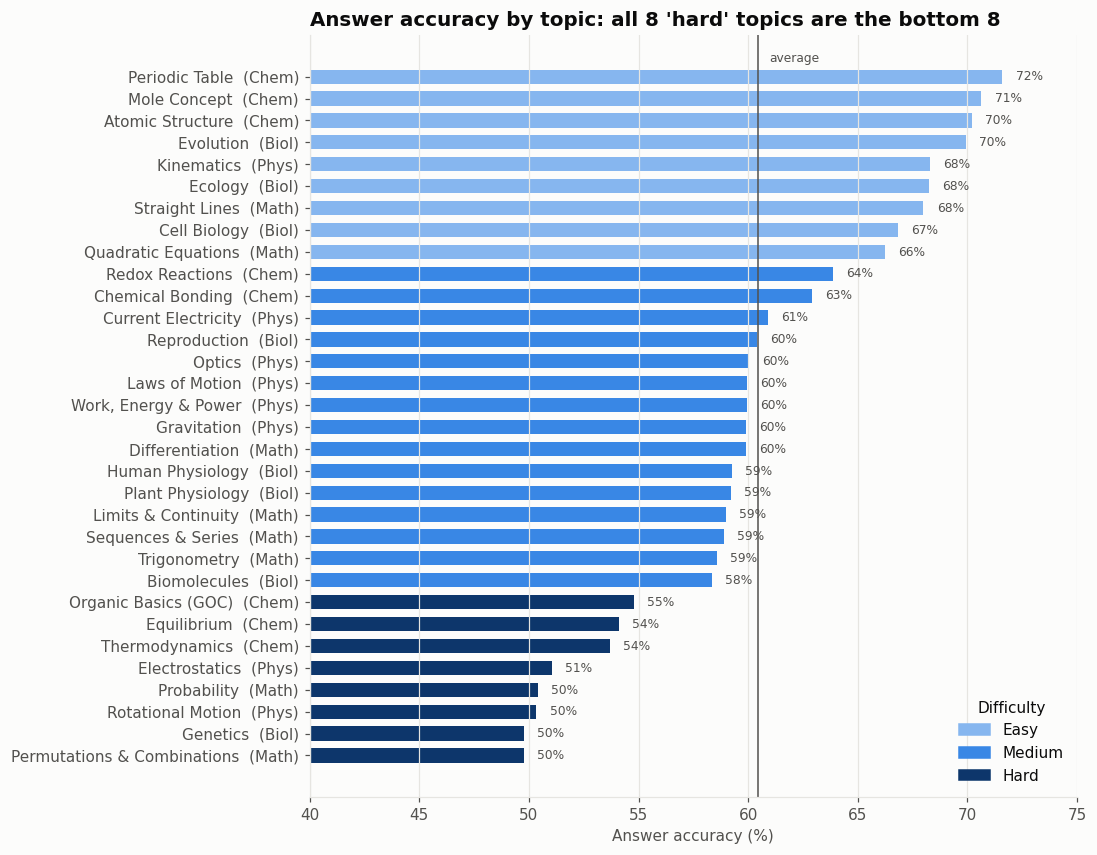

In [6]:
t = topics.sort_values("accuracy_pct")
t["label"] = t.topic_name + "  (" + t.subject.str[:4] + ")"
colors = t.difficulty.map({1: SEQ[0], 2: SEQ[1], 3: SEQ[3]})

fig, ax = plt.subplots(figsize=(9, 9))
ax.barh(t.label, t.accuracy_pct, color=colors, height=0.65)
for y, v in enumerate(t.accuracy_pct):
    ax.text(v + 0.6, y, f"{v:.0f}%", va="center", fontsize=8, color=INK2)
ax.axvline(t.accuracy_pct.mean(), color=INK2, lw=1)
ax.text(t.accuracy_pct.mean() + 0.5, len(t) - 0.3, "average", color=INK2, fontsize=8)
ax.set_xlim(40, 75); ax.grid(axis="y", visible=False)
ax.set_xlabel("Answer accuracy (%)")
ax.set_title("Answer accuracy by topic: all 8 'hard' topics are the bottom 8")
from matplotlib.patches import Patch
ax.legend(handles=[Patch(color=SEQ[0], label="Easy"), Patch(color=SEQ[1], label="Medium"),
                   Patch(color=SEQ[3], label="Hard")], title="Difficulty", loc="lower right")
save(fig, "01_topic_accuracy")

In [7]:
diff = q('''SELECT difficulty, ROUND(100.0*SUM(correct)/SUM(attempted),1) AS accuracy_pct
            FROM test_results JOIN topics USING(topic_id) GROUP BY difficulty''')
diff

,difficulty,accuracy_pct
0,1,69.1
1,2,60.3
2,3,51.9


**Insight:** Accuracy falls by about 8–9 points per difficulty level (69% → 60% → 52%). Four topics sit near 50% accuracy: **Permutations & Combinations, Genetics, Rotational Motion and Probability**. For these, students get only one in two questions right. These should get extra practice sessions and revision material first.

## 4. Do attendance and homework drive scores?

In [8]:
active_tested = summary[summary.tests_taken > 0]
r_att, p_att = stats.pearsonr(active_tested.attendance_pct, active_tested.avg_score_pct)
r_hw,  p_hw  = stats.pearsonr(active_tested.hw_submission_pct, active_tested.avg_score_pct)
print(f"Attendance vs score: r = {r_att:.2f} (p = {p_att:.1e})")
print(f"Homework   vs score: r = {r_hw:.2f} (p = {p_hw:.1e})")

bands = run_q(3)
bands

Attendance vs score: r = 0.28 (p = 1.5e-27)
Homework   vs score: r = 0.55 (p = 1.2e-117)


,attendance_band,students,avg_score_pct,avg_accuracy_pct,dropout_rate_pct
0,1) 90%+,274,45.8,64.6,0.0
1,2) 75-90%,654,41.0,60.8,1.1
2,3) 60-75%,492,36.5,57.3,18.7
3,4) Below 60%,79,25.0,46.2,46.8


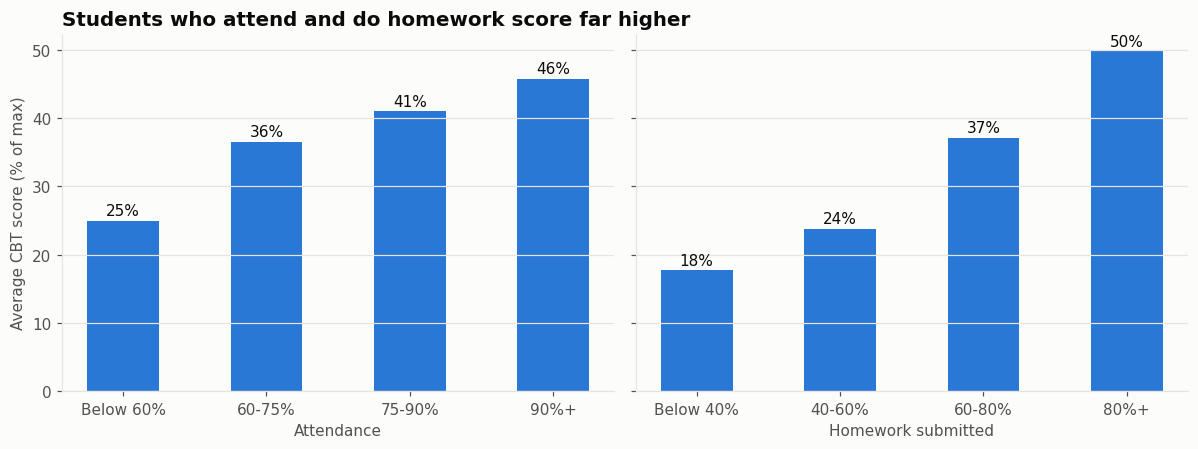

In [9]:
hw_bands = run_q(4)

fig, axes = plt.subplots(1, 2, figsize=(11, 4.2), sharey=True)
for ax, df, col, title in [
    (axes[0], bands.iloc[::-1], "attendance_band", "Attendance"),
    (axes[1], hw_bands.iloc[::-1], "homework_band", "Homework submitted"),
]:
    lbl = df[col].str[3:]
    ax.bar(lbl, df.avg_score_pct, color=BLUE, width=0.5)
    for x, v in enumerate(df.avg_score_pct):
        ax.text(x, v + 0.8, f"{v:.0f}%", ha="center", color=INK, fontsize=10)
    ax.set_xlabel(title); ax.grid(axis="x", visible=False)
axes[0].set_ylabel("Average CBT score (% of max)")
axes[0].set_title("Students who attend and do homework score far higher")
fig.tight_layout()
save(fig, "02_attendance_homework_vs_score")

**Insight:** Students with **90%+ attendance** average about 46%, while those **below 60%** average about 25%. That's a **~21-point gap**. Homework shows an even stronger link: from about 50% for regular submitters down to about 18% for those submitting under 40%. These are correlations, not proof of cause, but they show that engagement is the best early signal we have.

## 5. How did performance change over the term?

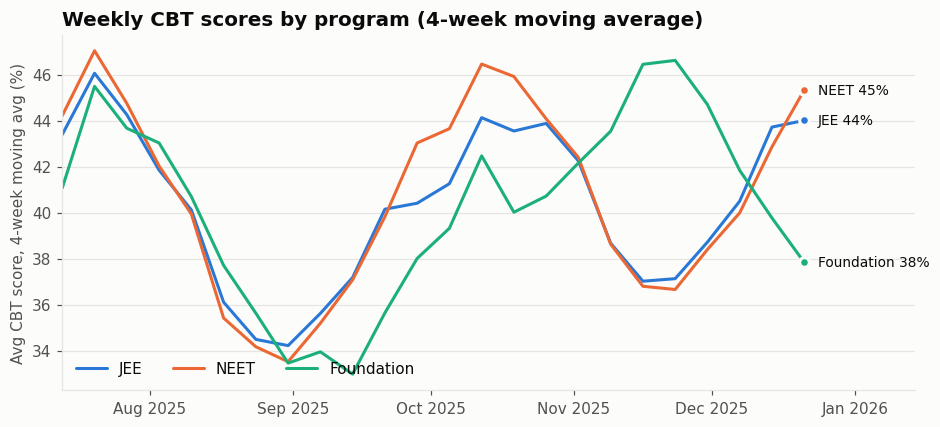

In [10]:
trend = run_q(6)
trend["test_date"] = pd.to_datetime(trend.test_date)

fig, ax = plt.subplots(figsize=(10, 4.2))
for prog, c in [("JEE", BLUE), ("NEET", ORANGE), ("Foundation", AQUA)]:
    d = trend[trend.program == prog]
    ax.plot(d.test_date, d.moving_avg_4wk, color=c, label=prog, solid_capstyle="round")
    ax.scatter(d.test_date.iloc[-1], d.moving_avg_4wk.iloc[-1], color=c, s=40, zorder=3,
               edgecolor=SURFACE, linewidth=2)
    ax.text(d.test_date.iloc[-1] + pd.Timedelta(days=3), d.moving_avg_4wk.iloc[-1],
            f"{prog} {d.moving_avg_4wk.iloc[-1]:.0f}%", va="center", color=INK, fontsize=9)
ax.set_ylabel("Avg CBT score, 4-week moving avg (%)")
ax.set_title("Weekly CBT scores by program (4-week moving average)")
ax.set_xlim(trend.test_date.min(), trend.test_date.max() + pd.Timedelta(days=24))
import matplotlib.dates as mdates
ax.xaxis.set_major_formatter(mdates.DateFormatter("%b %Y"))
ax.legend(loc="lower left", ncol=3); ax.grid(axis="x", visible=False)
save(fig, "03_score_trend")

In [11]:
run_q(13)

,batch_name,first_5_tests_pct,last_5_tests_pct,improvement_pts
0,NEET-12C,33.2,37.6,4.3
1,JEE-12B,41.1,45.0,3.8
2,NEET-11B,42.2,45.7,3.6
3,NEET-12A,39.7,42.9,3.3
4,NEET-11C,40.1,42.6,2.6
5,JEE-12A,44.3,46.3,1.9
6,JEE-11B,40.8,42.6,1.8
7,JEE-11A,42.1,43.6,1.5
8,Foundation-10A,41.9,43.0,1.1
9,JEE-11C,38.4,39.2,0.8


**Insight:** Scores follow the syllabus. They drop when the hardest topics come up (mid-August to early September, and again in mid-November for JEE and NEET), then recover on easier topics. So score dips come from topic difficulty, not from students falling behind. **14 of 18 batches ended the term higher than they started.** Four Foundation batches (9A, 9C, 10B, 10C) declined by 1–4 points and should be reviewed.

## 6. Online vs offline, and teachers

In [12]:
mode = run_q(8)
mode

,program,mode,students,avg_attendance_pct,avg_hw_submission_pct,avg_score_pct,dropout_rate_pct
0,Foundation,Offline,328,80.3,76.6,39.3,8.2
1,Foundation,Online,174,75.3,70.5,38.8,10.3
2,JEE,Offline,310,80.5,77.0,40.7,9.4
3,JEE,Online,202,75.1,69.9,37.9,11.9
4,NEET,Offline,311,80.6,77.2,41.9,8.7
5,NEET,Online,175,74.3,69.2,36.8,6.9


In [13]:
on  = summary.query("mode == 'Online'  and tests_taken > 0").avg_score_pct
off = summary.query("mode == 'Offline' and tests_taken > 0").avg_score_pct
t_stat, p_val = stats.ttest_ind(off, on, equal_var=False)
print(f"Offline avg score {off.mean():.1f}% vs Online {on.mean():.1f}%  |  Welch t-test p = {p_val:.4f}")
att_by_mode = summary.groupby("mode").attendance_pct.mean()
print(f"Offline attendance {att_by_mode['Offline']:.1f}% vs Online {att_by_mode['Online']:.1f}%")

Offline avg score 40.6% vs Online 37.8%  |  Welch t-test p = 0.0052
Offline attendance 80.5% vs Online 74.9%


In [14]:
teachers = run_q(7)
teachers.pivot_table(index="subject", values="accuracy_pct", aggfunc=["min", "max"]).round(1)

,min,max
,accuracy_pct,accuracy_pct
subject,,
Biology,58.7,64.3
Chemistry,57.8,67.0
Mathematics,57.2,63.3
Physics,57.5,60.7


**Insight:** Online students attend about **5.6 points less** and score about **2.8 points lower**, and the gap is statistically significant (p < 0.01). Across teachers of the same subject, accuracy varies by **3–9 points**. Pairing the top-ranked teacher in each subject with the others to share methods is a low-cost improvement. (Class sizes differ, so this is a starting point for review, not a performance rating.)

## 7. Dropout analysis

In [15]:
run_q(10)

,status,students,avg_attendance_pct,avg_hw_submission_pct,avg_score_pct,avg_tests_taken
0,Active,1363,79.9,76.1,40.5,20.0
1,Dropped,137,63.6,56.8,30.8,12.1


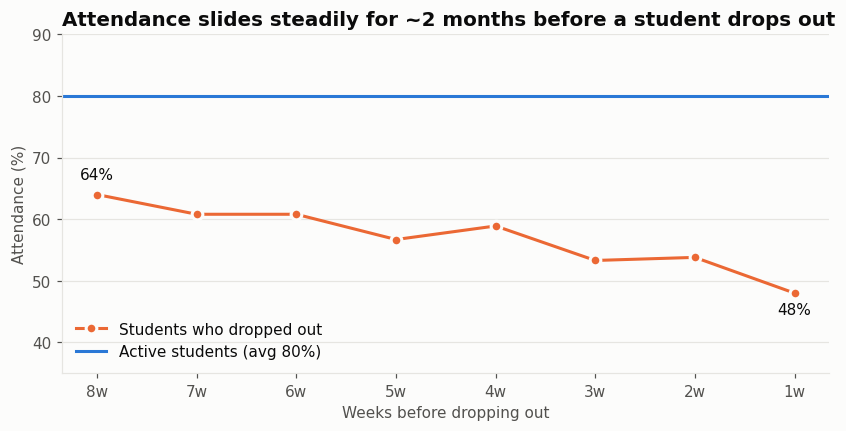

In [16]:
before = run_q(11)
overall = summary.query("status == 'Active'").attendance_pct.mean()

fig, ax = plt.subplots(figsize=(9, 4))
x = -before.weeks_before_dropout
ax.plot(x, before.attendance_pct, color=ORANGE, marker="o", markersize=7,
        markeredgecolor=SURFACE, markeredgewidth=2, label="Students who dropped out")
ax.axhline(overall, color=BLUE, lw=2, label=f"Active students (avg {overall:.0f}%)")
ax.text(x.iloc[-1], before.attendance_pct.iloc[-1] - 3.5, f"{before.attendance_pct.iloc[-1]:.0f}%",
        ha="center", color=INK, fontsize=10)
ax.text(x.iloc[0], before.attendance_pct.iloc[0] + 2.5, f"{before.attendance_pct.iloc[0]:.0f}%",
        ha="center", color=INK, fontsize=10)
ax.set_xticks(x); ax.set_xticklabels([f"{w}w" for w in before.weeks_before_dropout])
ax.set_xlabel("Weeks before dropping out"); ax.set_ylabel("Attendance (%)")
ax.set_ylim(35, 90); ax.grid(axis="x", visible=False); ax.legend(loc="lower left")
ax.set_title("Attendance slides steadily for ~2 months before a student drops out")
save(fig, "04_attendance_before_dropout")

**Insight:** Dropouts don't happen suddenly. Attendance is already about **16 points below** active students **8 weeks before** a student leaves, and keeps falling to about 48% in the final week. That gives the institute a **window of 1–2 months to intervene**.

### Early-warning model
Can we predict dropouts using **only the first 6 weeks** of data? (Using the whole term would leak the answer.) I use a simple, explainable logistic regression. The target is students who were still enrolled after week 6 but dropped out later.

In [17]:
from sklearn.linear_model import LogisticRegression
from sklearn.model_selection import train_test_split
from sklearn.metrics import roc_auc_score, classification_report
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import make_pipeline

CUTOFF = "2025-08-17"   # end of week 6
feat = q('''
WITH s AS (SELECT * FROM students WHERE join_date < :cut
           AND (dropout_date IS NULL OR dropout_date >= :cut)),
att AS (SELECT student_id, 100.0*AVG(CASE WHEN status <> 'Absent' THEN 1 ELSE 0 END) AS att_pct
        FROM attendance WHERE class_date < :cut GROUP BY student_id),
hw AS (SELECT s.student_id,
              100.0*COUNT(hs.homework_id)/COUNT(h.homework_id) AS hw_pct
       FROM s JOIN homework h ON h.batch_id = s.batch_id AND h.assigned_date >= s.join_date AND h.assigned_date < :cut
       LEFT JOIN homework_submissions hs ON hs.homework_id = h.homework_id AND hs.student_id = s.student_id
       GROUP BY s.student_id),
sc AS (SELECT student_id, AVG(score_pct) AS score_pct, COUNT(*) AS tests
       FROM v_student_test_scores WHERE test_date < :cut GROUP BY student_id)
SELECT s.student_id, b.mode, att.att_pct, hw.hw_pct, COALESCE(sc.score_pct, 0) AS score_pct,
       COALESCE(sc.tests, 0) AS tests, CASE WHEN s.status = 'Dropped' THEN 1 ELSE 0 END AS dropped_later
FROM s JOIN batches b USING(batch_id)
JOIN att USING(student_id) JOIN hw USING(student_id) LEFT JOIN sc USING(student_id)
''', cut=CUTOFF)
feat["online"] = (feat["mode"] == "Online").astype(int)
X, y = feat[["att_pct", "hw_pct", "score_pct", "tests", "online"]], feat.dropped_later
print(f"{len(feat)} students | {y.sum()} dropped later ({100*y.mean():.1f}%)")

X_tr, X_te, y_tr, y_te = train_test_split(X, y, test_size=0.3, stratify=y, random_state=42)
model = make_pipeline(StandardScaler(), LogisticRegression(class_weight="balanced", max_iter=1000))
model.fit(X_tr, y_tr)
proba = model.predict_proba(X_te)[:, 1]
print(f"ROC-AUC on held-out students: {roc_auc_score(y_te, proba):.2f}")
print(classification_report(y_te, proba >= 0.5, target_names=["stayed", "dropped"], digits=2))

1341 students | 123 dropped later (9.2%)
ROC-AUC on held-out students: 0.74
              precision    recall  f1-score   support

      stayed       0.95      0.69      0.80       366
     dropped       0.18      0.68      0.29        37

    accuracy                           0.69       403
   macro avg       0.57      0.68      0.54       403
weighted avg       0.88      0.69      0.75       403



In [18]:
coefs = pd.Series(model[-1].coef_[0], index=X.columns).sort_values()
coefs.rename("standardised_coefficient").round(2).to_frame()

,standardised_coefficient
att_pct,-0.42
hw_pct,-0.33
tests,-0.14
online,-0.11
score_pct,-0.00


In [19]:
# How many real dropouts are in the top 20% highest-risk students?
te = X_te.assign(risk=proba, dropped=y_te.values).sort_values("risk", ascending=False)
top = te.head(int(0.2 * len(te)))
print(f"Flagging the top 20% riskiest students catches {top.dropped.sum()} of {te.dropped.sum()} "
      f"dropouts ({100*top.dropped.sum()/te.dropped.sum():.0f}%)")

Flagging the top 20% riskiest students catches 19 of 37 dropouts (51%)


**Insight:** Early **attendance is the strongest predictor**, followed by homework submission. Using only the first 6 weeks, the model reaches a ROC-AUC of about 0.74. **Calling just the top 20% highest-risk students would reach about half of future dropouts**, compared with 20% if students were picked at random. That's a practical weekly call list for counsellors.

The same rule-based early-warning list is available in SQL (`Q9` in `sql/04_analysis_queries.sql`) and as the stored procedure `sp_at_risk_students(65, 50)` for MySQL.

In [20]:
at_risk = run_q(9)
print(f"{len(at_risk)} active students flagged; {(at_risk.risk_flags >= 2).sum()} with 2+ risk flags (call first)")
out = ROOT / "outputs"; out.mkdir(exist_ok=True)
at_risk.to_csv(out / "at_risk_students.csv", index=False)
at_risk.head(10)

269 active students flagged; 59 with 2+ risk flags (call first)


,student_id,student_name,batch_name,recent_attendance_pct,hw_submission_pct,earlier_score_pct,recent_score_pct,score_change,risk_flags
0,S0159,Aadhya Reddy,Foundation-9C,33.3,42.0,9.5,-4.2,-13.7,3
1,S0715,Kavya Das,JEE-11B,45.8,39.2,6.4,-4.0,-10.4,3
2,S0452,Karthik Menon,JEE-12C,50.0,47.2,29.9,19.0,-11.0,3
3,S1451,Lakshmi Nair,JEE-11A,50.0,47.2,14.7,0.2,-14.5,3
4,S1119,Bhavya Gowda,Foundation-10B,62.5,49.0,13.5,-1.5,-14.9,3
5,S0416,Neha Hegde,Foundation-9C,29.2,46.9,21.2,17.1,-4.1,2
6,S1000,Arjun Pillai,Foundation-10B,29.2,49.0,38.6,31.7,-7.0,2
7,S0628,Divya Pillai,NEET-12C,33.3,62.5,37.3,24.8,-12.5,2
8,S0827,Nikhil Naik,JEE-11A,41.7,73.6,47.5,28.8,-18.7,2
9,S1070,Meera Kumar,NEET-11C,41.7,40.3,9.4,11.0,1.6,2


## 8. Recommendations

| # | Finding | Recommendation | Expected impact |
|---|---|---|---|
| 1 | 8 hard topics have ~50–55% accuracy | Add weekly doubt-clearing and practice sets for P&C, Genetics, Rotational Motion, Probability, Electrostatics | Lift accuracy on the weakest topics |
| 2 | <60% attendance → ~25% avg score and ~47% dropout rate | Auto-SMS parents when weekly attendance drops below 65% | Earlier intervention |
| 3 | Attendance declines for ~8 weeks before dropout | Weekly counsellor calls to the top-20% risk list (model) or the 2+ flag list (SQL, 59 students) | Reduce the 9% dropout rate |
| 4 | Regular homework submitters (80%+) score 2–3x more than low submitters | Make homework status visible on the student dashboard; weekly reminders | Higher submission rate |
| 5 | Online batches attend ~5.6 pts less and score ~2.8 pts lower | Shorter live sessions + recorded-lecture check-ins for online batches | Close the online gap |
| 6 | 3–9 pt accuracy spread between teachers of the same subject | Peer observation / shared question banks led by top-ranked teacher per subject | More consistent results |

### Limitations
- The data is synthetic, so the specific numbers show the method, not real-world results.
- The correlations do not prove cause and effect; an A/B test of interventions would confirm impact.
- The model is intentionally simple and explainable. A production version would be retrained each term and monitored.

In [21]:
con.close()